# 07 · Business impact of the approval strategy

What would each score change if a lender re-screened the funded 2017 loans at a fixed approval
rate? This reports on models that are already chosen; nothing here selects a model.

**Read with care**

* All loans here were already approved by Lending Club, so "rejected" means re-screened out of
  funded loans. Applicants Lending Club declined are not observed.
* Only defaults in the first 12 months count. Later defaults are ignored, so profit is overstated.
* The economics in `src/business.py` are simplified: fixed average balance 0.85, exposure at default
  0.80, LGD 0.85, no funding or operating costs. These are assumptions, not estimates from data.
* `int_rate` is used only to value loans, never as a model feature. Lending Club set these rates,
  and they would change under another strategy.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import TARGET
from src.features_config import CATEGORICAL
from src.split import PROCESSED_PATH
from src.scoring import Models
from src.business import approved_mask, loan_profit, paired_difference, strategy_row

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160)
FIG, TABLES = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
RATES = [0.7, 0.8, 0.9]

samples = pd.read_parquet(PROCESSED_PATH)
oot = samples[samples["sample"] == "oot"].reset_index(drop=True)
models = Models({c: sorted(samples[c].dropna().astype(str).unique()) for c in CATEGORICAL})
pred = models.predict(oot)
y, amount, rate = oot[TARGET].to_numpy(), oot["loan_amnt"].to_numpy(), oot["int_rate"].to_numpy()
SCORES = {"Lending Club sub-grade": oot["sub_grade"].astype(str).rank(method="dense").to_numpy(),
          "Scorecard": pred["Scorecard"], "LightGBM monotone": pred["LightGBM monotone"]}
print(f"{len(oot):,} loans, default rate {y.mean():.2%}, lending ${amount.sum() / 1e9:.2f} bn")

296,484 loans, default rate 4.04%, lending $3.60 bn


## 1. Strategies at a fixed approval rate

In [2]:
rows = [{"strategy": "Approve all", **strategy_row(y, amount, rate, np.zeros(len(y)), 1.0)}]
rows += [{"strategy": n, **strategy_row(y, amount, rate, s, r)} for r in RATES for n, s in SCORES.items()]
strategies = pd.DataFrame(rows)
strategies["profit_musd"] = strategies["profit"] / 1e6
strategies.drop(columns="profit").round(4).to_csv(TABLES / "07_strategies.csv", index=False)
strategies.drop(columns="profit").round(4)

,strategy,approval_rate,default_rate,defaults_avoided_share,good_loans_rejected_share,profit_pct_of_lending,profit_musd
0,Approve all,1.0,0.0404,0.0000,0.0000,6.7159,241.9572
1,Lending Club sub-grade,0.7,0.0246,0.5735,0.2885,4.3299,155.9951
2,Scorecard,0.7,0.0276,0.5215,0.2907,5.0745,182.8201
3,LightGBM monotone,0.7,0.0237,0.5892,0.2878,4.7597,171.4804
4,Lending Club sub-grade,0.8,0.0282,0.4418,0.1898,5.0721,182.7354
5,Scorecard,0.8,0.0307,0.3925,0.1919,5.7211,206.1150
6,LightGBM monotone,0.8,0.0276,0.4539,0.1893,5.4762,197.2938
7,Lending Club sub-grade,0.9,0.0328,0.2685,0.0929,5.8837,211.9736
8,Scorecard,0.9,0.0348,0.2242,0.0948,6.2794,226.2314
9,LightGBM monotone,0.9,0.0321,0.2843,0.0922,6.1966,223.2468


## 2. LightGBM monotone minus the sub-grade, paired bootstrap

In [3]:
profit = loan_profit(y, amount, rate)
diff = pd.DataFrame({r: paired_difference(y, profit, approved_mask(SCORES["Lending Club sub-grade"], r),
                                          approved_mask(SCORES["LightGBM monotone"], r)) for r in RATES}).T
for c in ["profit_diff", "profit_low", "profit_high"]:
    diff[c] = diff[c] / 1e6
diff.index.name = "approval_rate"
diff.round(5).to_csv(TABLES / "07_vs_benchmark.csv")
diff.round(5)

,dr_diff,dr_low,dr_high,profit_diff,profit_low,profit_high
approval_rate,,,,,,
0.7,-0.00091,-0.00149,-0.00036,15.48522,14.08051,17.18881
0.8,-0.00061,-0.00110,-0.00014,14.55841,13.01456,16.24519
0.9,-0.00071,-0.00112,-0.00031,11.27319,9.60696,12.75823


## 3. Sensitivity to LGD

In [4]:
sens = pd.DataFrame({(lgd, n): {r: strategy_row(y, amount, rate, s, r, lgd)["profit"] / 1e6 for r in RATES}
                     for lgd in [0.7, 0.85, 0.95] for n, s in SCORES.items()})
sens.columns.names, sens.index.name = ["LGD", "score"], "approval_rate"
sens.round(1).to_csv(TABLES / "07_lgd_sensitivity.csv")
sens.round(1)

LGD                             0.70                                               0.85                                               0.95            \
score         Lending Club sub-grade Scorecard LightGBM monotone Lending Club sub-grade Scorecard LightGBM monotone Lending Club sub-grade Scorecard   
approval_rate                                                                                                                                          
0.7                            163.6     192.7             178.3                  156.0     182.8             171.5                  150.9     176.3   
0.8                            192.6     218.3             206.5                  182.7     206.1             197.3                  176.1     198.0   
0.9                            225.2     241.4             235.6                  212.0     226.2             223.2                  203.2     216.1   

LGD                              
score         LightGBM monotone  
approval_rate                    
0.7                       166.9  
0.8                       191.2  
0.9                       215.0

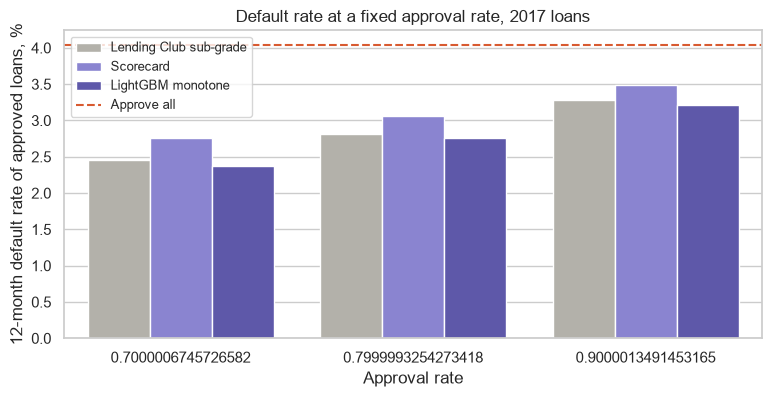

In [5]:
t = strategies[strategies["strategy"] != "Approve all"]
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=t, x="approval_rate", y=t["default_rate"] * 100, hue="strategy", ax=ax,
            palette=["#B4B2A9", "#7F77DD", "#534AB7"])
ax.axhline(y.mean() * 100, color="#D85A30", ls="--", label="Approve all")
ax.set_xlabel("Approval rate")
ax.set_ylabel("12-month default rate of approved loans, %")
ax.set_title("Default rate at a fixed approval rate, 2017 loans")
ax.legend(fontsize=9)
fig.savefig(FIG / "07_strategies.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Conclusions

### Default rate: the reliable result

| Approval rate | Sub-grade | Scorecard | LightGBM monotone | LightGBM minus sub-grade (95% CI) |
|---|---|---|---|---|
| 70% | 2.46% | 2.76% | **2.37%** | −0.09 pp (−0.15 to −0.04) |
| 80% | 2.82% | 3.07% | **2.76%** | −0.06 pp (−0.11 to −0.01) |
| 90% | 3.28% | 3.48% | **3.21%** | −0.07 pp (−0.11 to −0.03) |

Approving all gives 4.04%. At 80% approval, LightGBM monotone avoids 45.4% of 12-month defaults
against 44.2% for the sub-grade, about 145 more of the 11,978 defaults, while rejecting 18.9% of
good loans. The gain over the lender's grade is real but small. Most of the benefit of screening
comes from any reasonable score, and the scorecard is the weakest of the three.

### Profit: do not use it to rank models

The 12-month profit table is **not a valid basis for a decision**. It says approving everyone is
best ($242m) and that the scorecard earns more than LightGBM despite more defaults. Both results
come from the setup: a year of interest is counted, but defaults after month 12, about three
quarters of lifetime defaults in matured 2010–2015 vintages, are not. Higher-rate, riskier loans
therefore look profitable, and a score that keeps them looks better. LightGBM's profit lead over
the sub-grade ($11–15m, intervals exclude zero) has the same limit.

A meaningful profit comparison needs lifetime cash flows, funding and operating costs. Lending
Club's rates also would not stay the same under another strategy.
